In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, classification_report,
                              precision_score, recall_score, f1_score, accuracy_score)
import seaborn as sns

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape :", x_test.shape)
print("Testing labels shape :", y_test.shape)

# Normalize pixel values to [0, 1] -- used throughout the rest of the notebook
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm  = x_test.astype("float32") / 255.0

y_train_flat = y_train.flatten()
y_test_flat  = y_test.flatten()


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2571s 15us/step
Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing images shape : (10000, 32, 32, 3)
Testing labels shape : (10000, 1)


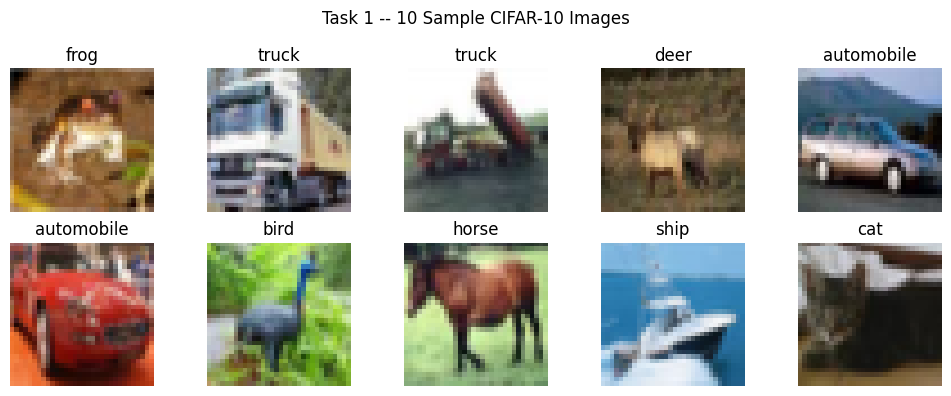

In [16]:
# --- Mandatory Plot 1: Sample Images ---
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train_flat[i]])
    plt.axis('off')
plt.suptitle("Task 1 -- 10 Sample CIFAR-10 Images")
plt.tight_layout()

plt.savefig("sample_images.eps",dpi=600)
plt.show()




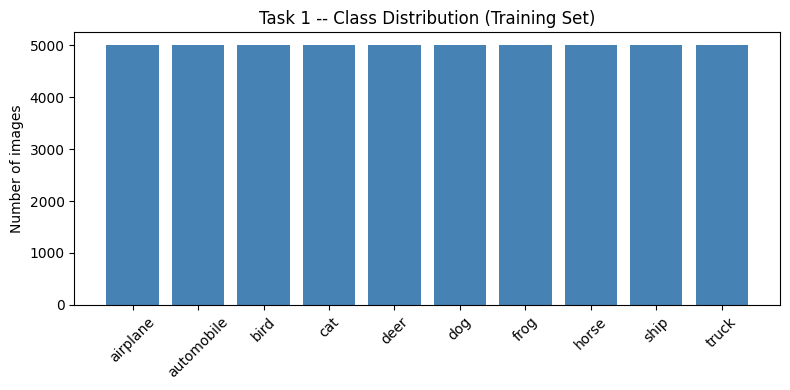

In [17]:
# --- Mandatory Plot 2: Class Distribution ---
unique, counts = np.unique(y_train_flat, return_counts=True)
plt.figure(figsize=(8, 4))
plt.bar([class_names[i] for i in unique], counts, color='steelblue')
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("Task 1 -- Class Distribution (Training Set)")
plt.tight_layout()

plt.savefig("class_distribution.eps",dpi=600)
plt.show()




## Task 2 — Convolution Layer: Compare Kernel Sizes (3x3, 5x5, 7x7)

Using the output-size formula from the manual:

$$\text{Output} = \frac{N - F + 2P}{S} + 1$$

For a 32x32 input, stride 1, no padding (Valid), we predict the feature map size for each kernel,
then confirm it by actually building a `Conv2D` layer and reading `.output_shape`.

In [18]:
def output_size(N, F, P, S):
    return (N - F + 2 * P) // S + 1

N, P, S = 32, 0, 1
kernel_sizes = [3, 5, 7]

print(f"{'Kernel':<10}{'Predicted (formula)':<22}{'Actual (Keras)'}")
for F in kernel_sizes:
    predicted = output_size(N, F, P, S)
    conv_layer = layers.Conv2D(filters=8, kernel_size=F, strides=S, padding='valid',
                                input_shape=(32, 32, 3))
    test_model = models.Sequential([conv_layer])
    actual = test_model.output_shape[1]
    print(f"{F}x{F:<7}{predicted}x{predicted:<19}{actual}x{actual}")


Kernel    Predicted (formula)   Actual (Keras)
3x3      30x30                 30x30
5x5      28x28                 28x28
7x7      26x26                 26x26


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Record these three feature-map sizes in your report table (Task 2 requires you to record them).

## Task 3 — Hyperparameter Study: Stride and Padding

We compare stride = 1 vs stride = 2, and padding = 'same' vs padding = 'valid',
computing output dimensions both by formula and by building the actual layer.

In [19]:
configs = [
    {"stride": 1, "padding": "valid"},
    {"stride": 2, "padding": "valid"},
    {"stride": 1, "padding": "same"},
    {"stride": 2, "padding": "same"},
]

F = 3
N = 32
print(f"{'Stride':<10}{'Padding':<12}{'Output Size (Keras)'}")
for cfg in configs:
    conv_layer = layers.Conv2D(filters=8, kernel_size=F, strides=cfg["stride"],
                                padding=cfg["padding"], input_shape=(32, 32, 3))
    test_model = models.Sequential([conv_layer])
    out = test_model.output_shape[1]
    print(f"{cfg['stride']:<10}{cfg['padding']:<12}{out}x{out}")




Stride    Padding     Output Size (Keras)
1         valid       30x30
2         valid       15x15
1         same        32x32
2         same        16x16


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step
Feature maps shape: (1, 32, 32, 32)


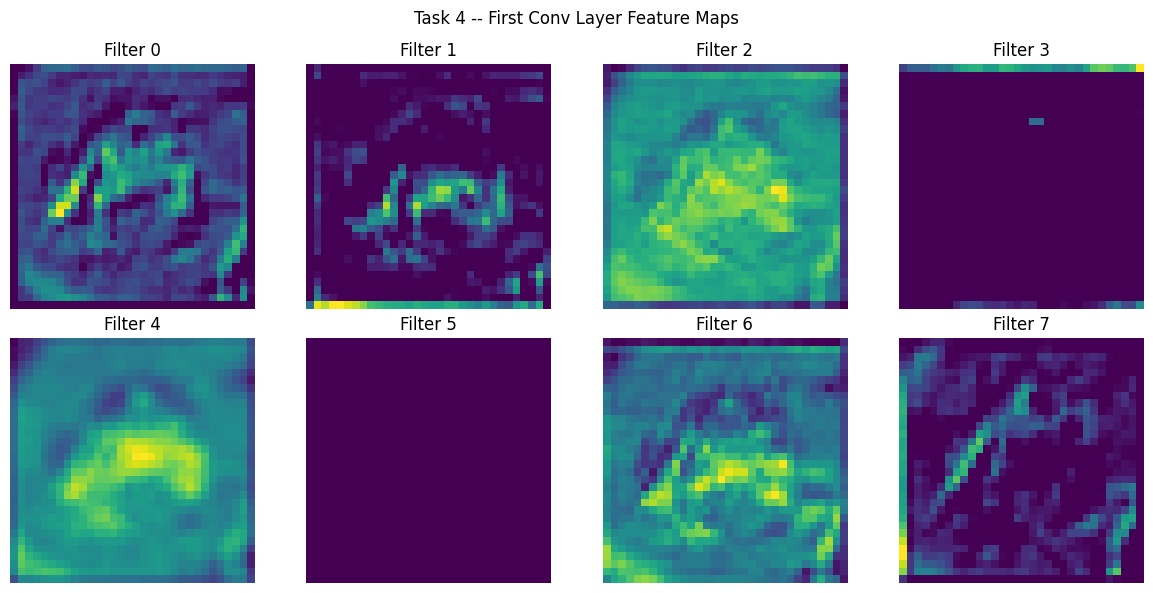

In [21]:
feature_map_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3))
])

sample_image = x_train_norm[0:1]  # keep batch dimension
feature_maps = feature_map_model.predict(sample_image)
print("Feature maps shape:", feature_maps.shape)  # (1, 32, 32, 32) -> 32 filters

# --- Mandatory Plot 7: Feature Maps ---
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title(f"Filter {i}")
    plt.axis('off')
plt.suptitle("Task 4 -- First Conv Layer Feature Maps")
plt.tight_layout()

plt.savefig("feature_maps.png")
plt.show()




In [9]:
def build_pooling_model(pool_type="max"):
    pool_layer = layers.MaxPooling2D((2, 2)) if pool_type == "max" else layers.AveragePooling2D((2, 2))
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
        pool_layer,
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)) if pool_type == "max" else layers.AveragePooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

max_model = build_pooling_model("max")
avg_model = build_pooling_model("average")

print("Max Pooling model output shape after first pool:",
      models.Sequential(max_model.layers[:2]).output_shape)
print("Average Pooling model output shape after first pool:",
      models.Sequential(avg_model.layers[:2]).output_shape)

# Train both briefly (5 epochs) just to compare pooling behavior -- Task 6 does the full 20-epoch run
history_max = max_model.fit(x_train_norm, y_train_flat, epochs=5, batch_size=32,
                             validation_data=(x_test_norm, y_test_flat), verbose=1)
history_avg = avg_model.fit(x_train_norm, y_train_flat, epochs=5, batch_size=32,
                             validation_data=(x_test_norm, y_test_flat), verbose=1)

print("Max Pooling final val accuracy:", history_max.history['val_accuracy'][-1])
print("Average Pooling final val accuracy:", history_avg.history['val_accuracy'][-1])



Max Pooling model output shape after first pool: (None, 16, 16, 32)
Average Pooling model output shape after first pool: (None, 16, 16, 32)
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.4902 - loss: 1.4254 - val_accuracy: 0.5983 - val_loss: 1.1366
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6329 - loss: 1.0512 - val_accuracy: 0.6462 - val_loss: 1.0092
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6784 - loss: 0.9226 - val_accuracy: 0.6718 - val_loss: 0.9561
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7079 - loss: 0.8377 - val_accuracy: 0.6762 - val_loss: 0.9530
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7310 - loss: 0.7722 - val_accuracy: 0.6859 - val_loss: 0.9293
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.4595 - loss: 1.5060 - val_accuracy: 0.5546 - val_loss: 1.2485
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5871 - loss: 1.17

In [10]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3)),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same'),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    x_train_norm, y_train_flat,
    epochs=20,
    batch_size=32,
    validation_data=(x_test_norm, y_test_flat),
    verbose=1
)


Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5129 - loss: 1.3648 - val_accuracy: 0.6231 - val_loss: 1.0699
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6531 - loss: 0.9922 - val_accuracy: 0.6689 - val_loss: 0.9472
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7005 - loss: 0.8559 - val_accuracy: 0.6797 - val_loss: 0.9254
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7368 - loss: 0.7567 - val_accuracy: 0.6863 - val_loss: 0.9194
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7666 - loss: 0.6717 - val_accuracy: 0.6833 - val_loss: 0.9588
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7933 - loss: 0.5930 - val_accuracy: 0.6804 - val_loss: 1.0241
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8199 - loss: 0.5205 - val_accuracy: 0.6766 - val_loss: 1.1085
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8417 - loss: 0.4587 -

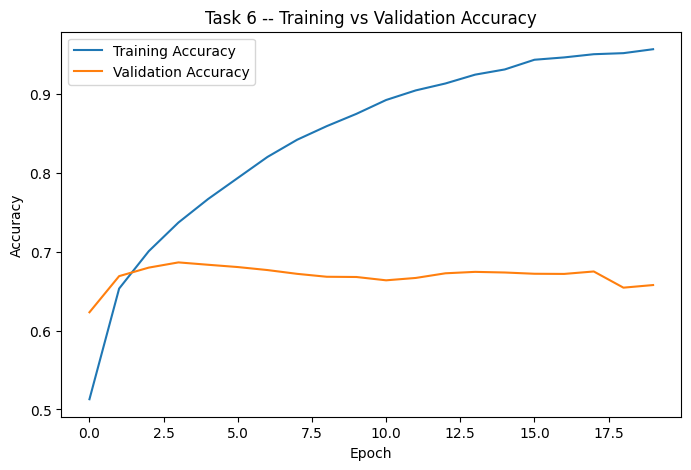

In [22]:
# --- Mandatory Plot 3 & 4: Training/Validation Accuracy ---
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Task 6 -- Training vs Validation Accuracy")
plt.legend()

plt.savefig("training_vs_validation_accuracy.eps",dpi=600)
plt.show()



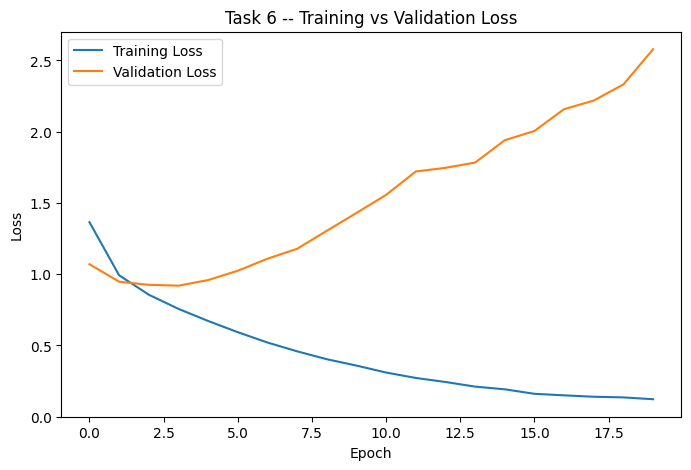

In [23]:
# --- Mandatory Plot 5 & 6: Training/Validation Loss ---
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Task 6 -- Training vs Validation Loss")
plt.legend()

plt.savefig("training_vs_validation_loss.eps",dpi=600)
plt.show()



In [14]:
y_pred_probs = model.predict(x_test_norm)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test_flat, y_pred)
prec = precision_score(y_test_flat, y_pred, average='macro')
rec = recall_score(y_test_flat, y_pred, average='macro')
f1 = f1_score(y_test_flat, y_pred, average='macro')

print(f"Test Accuracy : {acc:.4f}")
print(f"Precision (macro): {prec:.4f}")
print(f"Recall (macro)   : {rec:.4f}")
print(f"F1-score (macro) : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test_flat, y_pred, target_names=class_names))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Accuracy : 0.6576
Precision (macro): 0.6723
Recall (macro)   : 0.6576
F1-score (macro) : 0.6597

Classification Report:

              precision    recall  f1-score   support

    airplane       0.69      0.72      0.70      1000
  automobile       0.83      0.76      0.79      1000
        bird       0.60      0.51      0.55      1000
         cat       0.44      0.51      0.47      1000
        deer       0.58      0.59      0.58      1000
         dog       0.49      0.61      0.55      1000
        frog       0.87      0.55      0.67      1000
       horse       0.69      0.75      0.72      1000
        ship       0.76      0.82      0.79      1000
       truck       0.77      0.76      0.76      1000

    accuracy                           0.66     10000
   macro avg       0.67      0.66      0.66     10000
weighted avg       0.67      0.66      0.66     10000



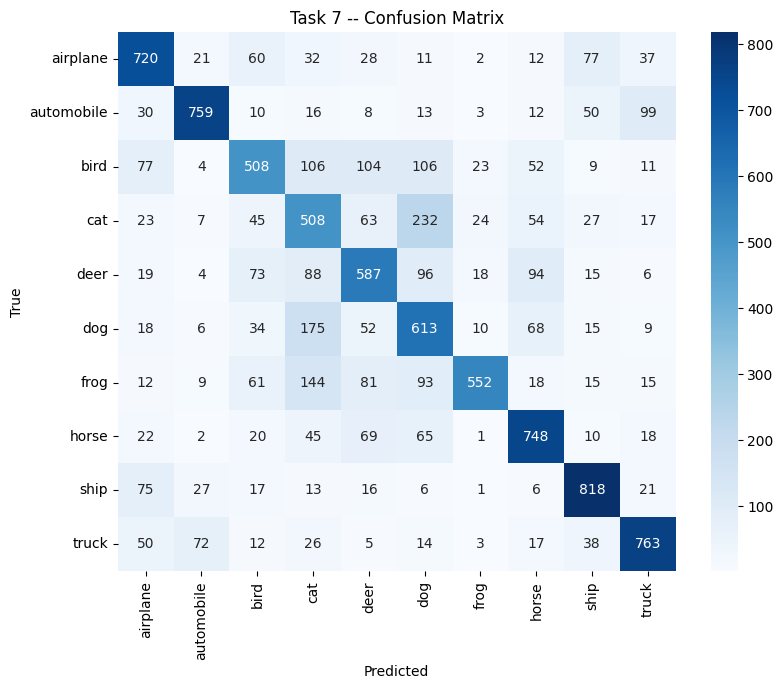

In [24]:
# --- Mandatory Plot 8: Confusion Matrix ---
cm = confusion_matrix(y_test_flat, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Task 7 -- Confusion Matrix")

plt.savefig("confusion_matrix.eps",dpi=600)
plt.show()


In [ ]:
total_params = model.count_params()
print("Total trainable parameters:", total_params)


Total trainable parameters: 545098


In [ ]:
# Verification of Exercise 1 and 2 using Keras
ex1_layer = layers.Conv2D(filters=1, kernel_size=5, strides=2, padding='valid',
                           input_shape=(64+4, 64+4, 1))  # manually padding by 2 on each side emulated via input size
# Simpler: use ZeroPadding2D to add padding=2, then a valid conv with stride 2
ex1_model = models.Sequential([
    layers.ZeroPadding2D(padding=2, input_shape=(64, 64, 1)),
    layers.Conv2D(1, (5, 5), strides=2, padding='valid')
])
print("Exercise 1 -- Output shape:", ex1_model.output_shape)  # expect (None, 32, 32, 1)

ex2_model = models.Sequential([
    layers.Conv2D(64, (3, 3), padding='valid', input_shape=(32, 32, 3))
])
print("Exercise 2 -- Trainable parameters:", ex2_model.count_params())  # expect 1792


Exercise 1 -- Output shape: (None, 32, 32, 1)
Exercise 2 -- Trainable parameters: 1792


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/zero_padding2d.py:72: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
